## Data loading

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
from init_df import body_df, title_df, interactions_df, embeddings_subreddits_df, embeddings_users_df
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
import umap.umap_ as umap

c:\Users\natha\anaconda3\envs\ada\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
interactions_df

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,Number of characters,Number of characters without counting white space,Fraction of alphabetical characters,Fraction of digits,Fraction of uppercase characters,...,LIWC_Death,LIWC_Assent,LIWC_Dissent,LIWC_Nonflu,LIWC_Filler,TYPE,YEAR,MONTH,WEEK,DAY
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.0,0.0,0.0,0.000000,0.000000,body,2013,12,1,31
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,101.0,98.0,0.742574,0.019802,0.049505,...,0.0,0.0,0.0,0.000000,0.000000,body,2013,12,1,31
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,85.0,85.0,0.752941,0.023529,0.082353,...,0.0,0.0,0.0,0.000000,0.000000,body,2014,1,1,1
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.0,0.0,0.0,0.020833,0.005208,body,2013,12,1,31
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,715.0,622.0,0.777622,0.006993,0.025175,...,0.0,0.0,0.0,0.000000,0.008333,body,2014,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
858483,seattleshitshow,seattlewa,68iptp,2017-04-27 11:07:31,-1,83.0,70.0,0.783133,0.000000,0.108434,...,0.0,0.0,0.0,0.000000,0.000000,title,2017,4,17,27
858484,peoplewhosayheck,spiderman,68iqh6s,2017-04-30 16:36:07,1,121.0,105.0,0.719008,0.016529,0.099174,...,0.0,0.0,0.0,0.000000,0.000000,title,2017,4,17,30
858485,vzla,wtf,68iqkcs,2017-04-30 15:50:07,1,68.0,58.0,0.764706,0.000000,0.147059,...,0.0,0.0,0.0,0.000000,0.000000,title,2017,4,17,30
858486,denverbroncos,nfl,68iqt8,2017-04-30 16:11:30,-1,96.0,79.0,0.770833,0.000000,0.072917,...,0.0,0.0,0.0,0.000000,0.050000,title,2017,4,17,30


# Propagation analysis 

In [17]:
# Make a copy of the embeddings dataframe
embeddings_with_sentiment = embeddings_subreddits_df.copy()

# Compute mean compound sentiment for each subreddit from the interactions dataframe
mean_sentiment = (
    interactions_df.groupby("SOURCE_SUBREDDIT")["Compound sentiment calculated by VADER"]
    .mean()
    .rename("mean_compound_sentiment")
)

# Merge it with the embeddings
embeddings_with_sentiment = embeddings_with_sentiment.merge(
    mean_sentiment, 
    left_on="SUBREDDIT",
    right_index=True, 
    how="left"
)
embeddings_with_sentiment.head()

,SUBREDDIT,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,...,emb_291,emb_292,emb_293,emb_294,emb_295,emb_296,emb_297,emb_298,emb_299,mean_compound_sentiment
0,spiders,0.158972,0.285813,0.226329,-0.183338,-0.163159,-0.188910,0.422705,0.168602,0.178193,...,0.184655,0.111942,-1.125799,0.223129,-0.387323,-0.234882,-0.252297,-0.054315,0.500009,0.213320
1,askreddit,-0.499114,0.323983,-0.424809,-0.222705,-0.327201,0.412856,1.040088,0.996697,-1.256240,...,0.226658,0.535705,0.039861,-0.027087,-0.239952,0.554510,0.676439,-0.328846,0.941547,0.167969
2,globaloffensivetrade,-0.023145,-1.199374,1.661484,-1.025296,1.424670,-1.179507,-1.035703,0.329301,-0.567272,...,-1.235703,-0.326850,4.381238,-1.965378,-2.369674,-0.615389,2.010601,-0.919314,-2.149625,0.402628
3,fireteams,2.492506,-2.529917,-0.448484,-3.543441,-0.586122,-0.101517,1.837567,-0.215715,-2.460388,...,0.969291,0.497958,2.941132,2.423561,1.315691,-0.959618,0.151845,-0.852492,-0.467526,0.497767
4,funny,-0.819370,-0.865261,0.301753,0.018787,0.201029,0.070462,0.903895,1.038460,-0.306950,...,0.830233,-0.137822,-2.204667,-0.162008,0.390291,-0.556404,0.322684,0.641634,1.320716,0.069636


### Mapping all subreddits

c:\Users\natha\anaconda3\envs\ada\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


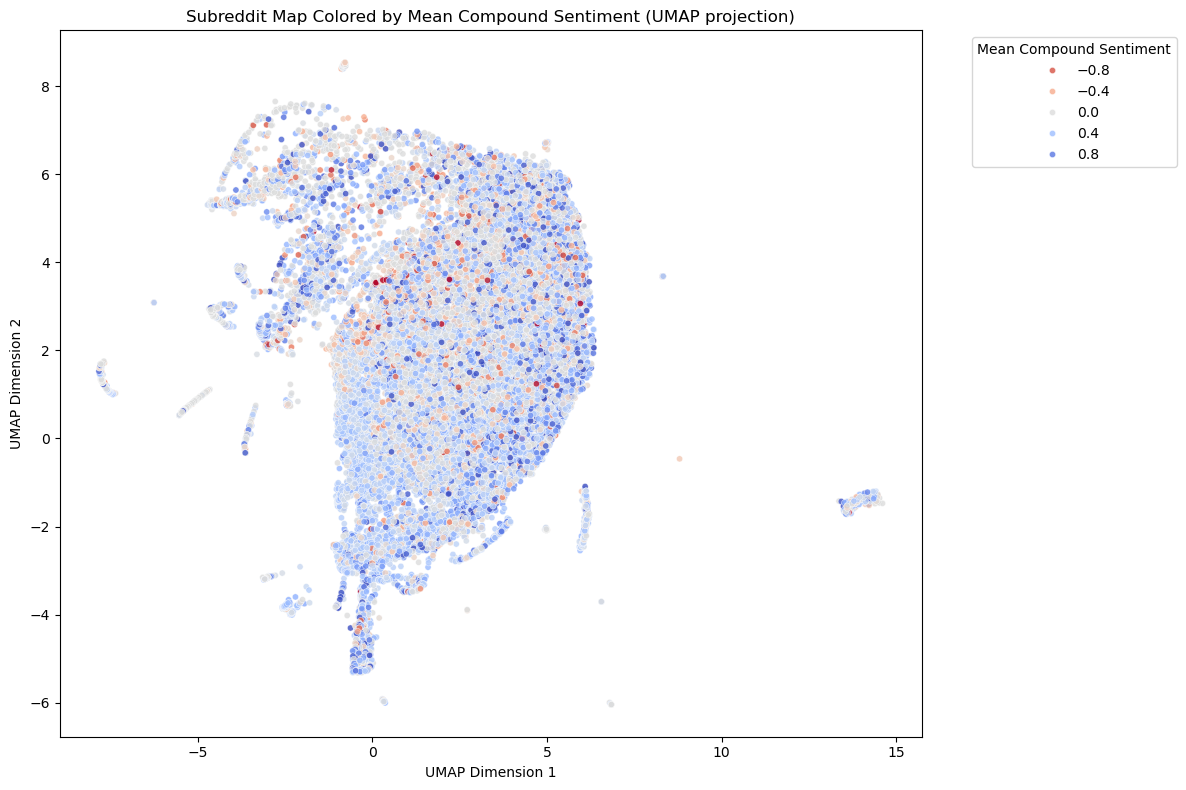

In [9]:
# === Identify embedding columns ===
embedding_cols = [c for c in embeddings_with_sentiment.columns if c not in ["SUBREDDIT", "mean_compound_sentiment"]]

# === Reduce 300D embeddings to 2D using UMAP ===
reducer = umap.UMAP(
    n_neighbors=30,         # controls local vs global structure
    min_dist=0.1,           # smaller = tighter clusters
    n_components=2,
    random_state=42
)
embedding_2d = reducer.fit_transform(embeddings_with_sentiment[embedding_cols])

# === Add new 2D coordinates ===
embeddings_with_sentiment["x"] = embedding_2d[:, 0]
embeddings_with_sentiment["y"] = embedding_2d[:, 1]

# === Plot ===
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=embeddings_with_sentiment,
    x="x", y="y",
    hue="mean_compound_sentiment",
    palette="coolwarm_r",  
    s=20,
    alpha=0.8
)
plt.title("Subreddit Map Colored by Mean Compound Sentiment (UMAP projection)")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title="Mean Compound Sentiment", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Mapping most active subreddits 

c:\Users\natha\anaconda3\envs\ada\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


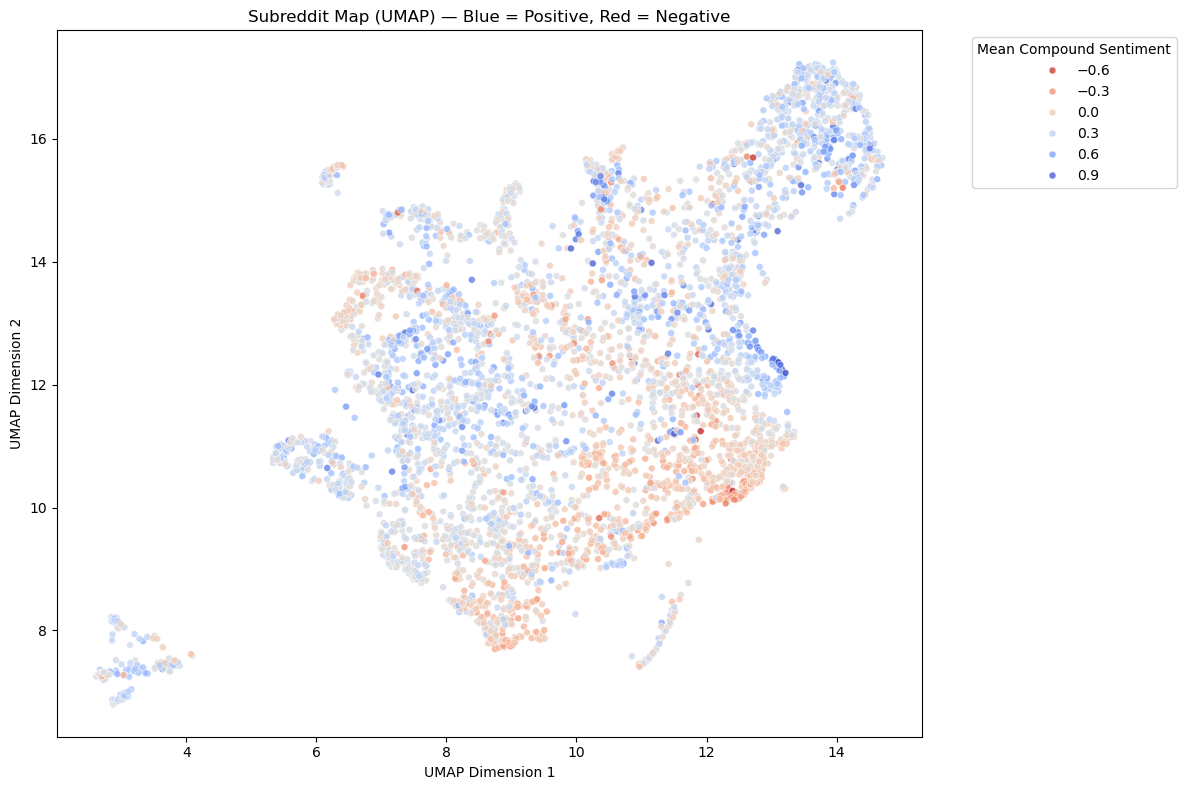

In [19]:
# === Count subreddit activity ===
# Here we assume `interactions_df` contains all subreddit interactions
activity_counts = interactions_df["SOURCE_SUBREDDIT"].value_counts()

# Keep only subreddits with at least N posts/interactions
N = 20  # adjust threshold depending on your dataset size
active_subs = activity_counts[activity_counts > N].index

# Filter embeddings & sentiment data to only active subreddits
filtered = embeddings_subreddits_df[embeddings_subreddits_df["SUBREDDIT"].isin(active_subs)]

# Merge mean sentiment data
embeddings_with_sentiment = filtered.merge(
    mean_sentiment, left_on="SUBREDDIT", right_on="SOURCE_SUBREDDIT", right_index=True, how="left"
).fillna(0)

# === Reduce 300D embeddings to 2D using UMAP ===
embedding_cols = [c for c in embeddings_with_sentiment.columns if c not in ["SUBREDDIT", "mean_compound_sentiment"]]
embedding_cols = embeddings_with_sentiment.select_dtypes(include='number').columns.tolist()

reducer = umap.UMAP(
    n_neighbors=30,
    min_dist=0.1,
    n_components=2,
    random_state=42
)
embedding_2d = reducer.fit_transform(embeddings_with_sentiment[embedding_cols])

# Add coordinates
embeddings_with_sentiment["x"] = embedding_2d[:, 0]
embeddings_with_sentiment["y"] = embedding_2d[:, 1]

# === Plot with inverted palette (blue = positive, red = negative) ===
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=embeddings_with_sentiment,
    x="x", y="y",
    hue="mean_compound_sentiment",
    palette="coolwarm_r",   # 🔁 '_r' reverses the palette
    s=25,
    alpha=0.8
)
plt.title("Subreddit Map (UMAP) — Blue = Positive, Red = Negative")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")
plt.legend(title="Mean Compound Sentiment", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Weekly evolution

In [28]:
import matplotlib.animation as animation

c:\Users\natha\anaconda3\envs\ada\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\natha\AppData\Local\Temp\ipykernel_31932\8714780.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_embeddings['x'] = embedding_2d[:, 0]
C:\Users\natha\AppData\Local\Temp\ipykernel_31932\8714780.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_embeddings['y'] = embedding_2d[:, 1]


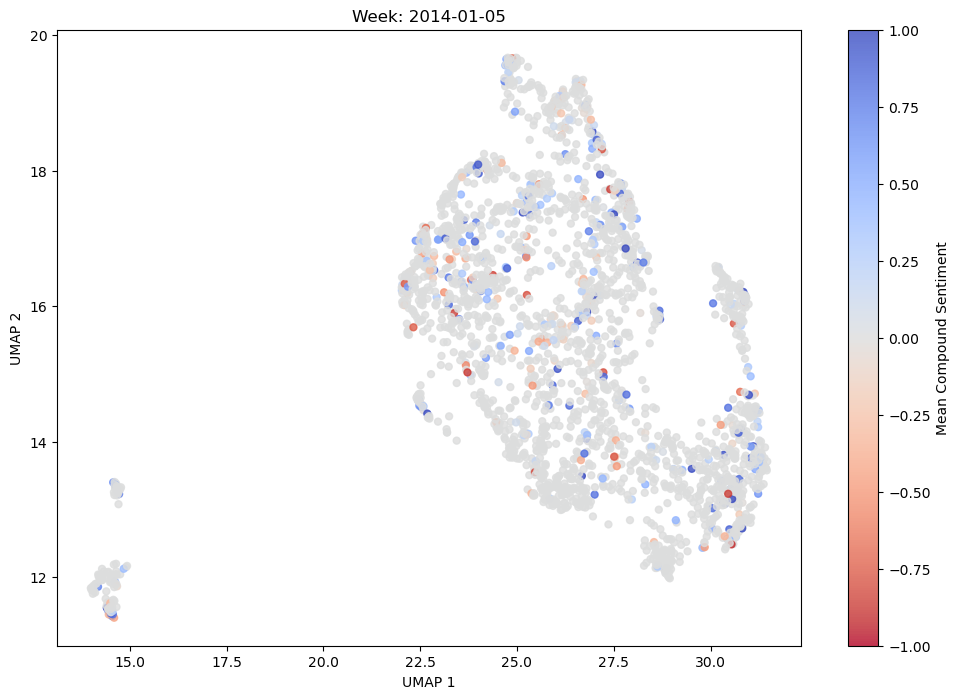

In [ ]:
# --- Parameters ---
N = 50  # minimum number of posts to be considered active
freq = "W"  # weekly aggregation
fps = 2  # frames per second in GIF

# --- Filter active subreddits ---
activity_counts = interactions_df["SOURCE_SUBREDDIT"].value_counts()
active_subs = activity_counts[activity_counts > N].index
filtered_embeddings = embeddings_subreddits_df[embeddings_subreddits_df["SUBREDDIT"].isin(active_subs)]

# --- Compute weekly mean compound sentiment per subreddit ---
interactions_df['TIMESTAMP'] = pd.to_datetime(interactions_df['TIMESTAMP'])
weekly_sentiment = (
    interactions_df[interactions_df['SOURCE_SUBREDDIT'].isin(active_subs)]
    .groupby([pd.Grouper(key='TIMESTAMP', freq=freq), 'SOURCE_SUBREDDIT'])
    ["Compound sentiment calculated by VADER"]
    .mean()
    .reset_index()
)

# --- Fill missing weeks with 0 ---
all_weeks = pd.date_range(weekly_sentiment['TIMESTAMP'].min(), weekly_sentiment['TIMESTAMP'].max(), freq=freq)
all_subs = filtered_embeddings['SUBREDDIT'].unique()
weekly_sentiment = (
    pd.MultiIndex.from_product([all_weeks, all_subs], names=['TIMESTAMP', 'SOURCE_SUBREDDIT'])
    .to_frame(index=False)
    .merge(weekly_sentiment, on=['TIMESTAMP', 'SOURCE_SUBREDDIT'], how='left')
    .fillna(0)
)

# --- Reduce embeddings to 2D once (UMAP) ---
embedding_cols = [c for c in filtered_embeddings.columns if c != 'SUBREDDIT']
reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, n_components=2, random_state=42)
embedding_2d = reducer.fit_transform(filtered_embeddings[embedding_cols])
filtered_embeddings['x'] = embedding_2d[:, 0]
filtered_embeddings['y'] = embedding_2d[:, 1]

# --- Merge 2D coordinates into weekly sentiment ---
weekly_embeddings = weekly_sentiment.merge(
    filtered_embeddings[['SUBREDDIT', 'x', 'y']],
    left_on='SOURCE_SUBREDDIT', right_on='SUBREDDIT', how='left'
)

# --- Animate ---
weeks = sorted(weekly_embeddings['TIMESTAMP'].unique())
fig, ax = plt.subplots(figsize=(12, 8))

# Initial scatter
data0 = weekly_embeddings[weekly_embeddings['TIMESTAMP'] == weeks[0]]
sc = ax.scatter(data0['x'], data0['y'], c=data0["Compound sentiment calculated by VADER"], cmap='coolwarm_r', vmin=-1, vmax=1, s=25, alpha=0.8)
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
title = ax.set_title(f"Week: {weeks[0].date()}")

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Mean Compound Sentiment')

def update(frame):
    data = weekly_embeddings[weekly_embeddings['TIMESTAMP'] == weeks[frame]]
    sc.set_offsets(data[['x', 'y']].values)
    sc.set_array(data["Compound sentiment calculated by VADER"].values)
    title.set_text(f"Week: {weeks[frame].date()}")
    return sc, title

ani = animation.FuncAnimation(fig, update, frames=len(weeks), blit=False, repeat=False)
ani.save('weekly_sentiment_evolution.gif', writer='pillow', fps=fps)

### Daily evolution

c:\Users\natha\anaconda3\envs\ada\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\natha\AppData\Local\Temp\ipykernel_31932\1541322319.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_embeddings['x'] = embedding_2d[:, 0]
C:\Users\natha\AppData\Local\Temp\ipykernel_31932\1541322319.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_embeddings['y'] = embedding_2d[:, 1]


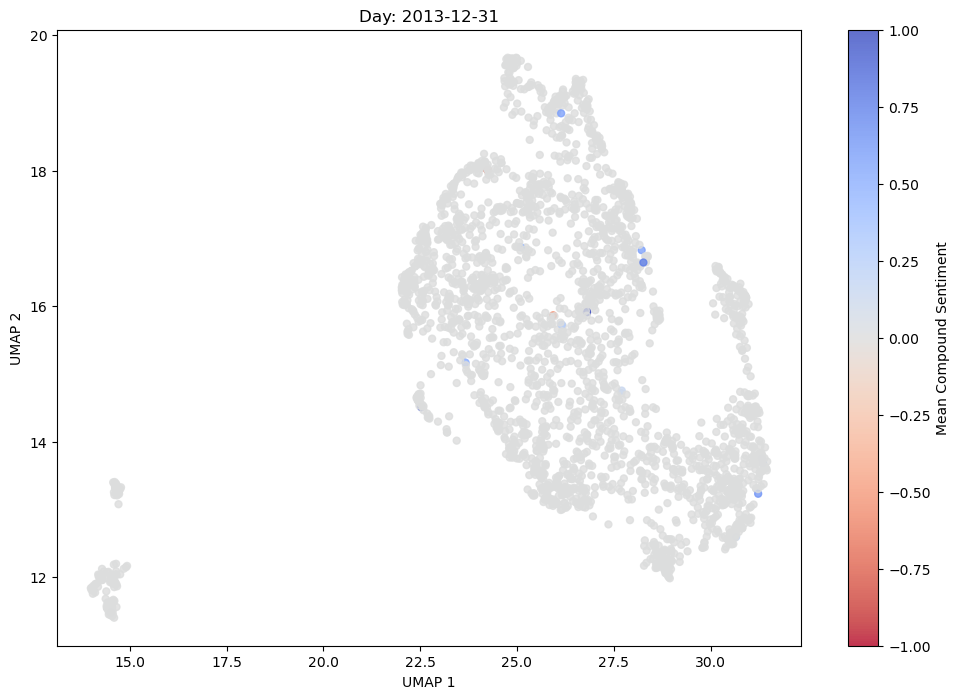

In [30]:
# --- Parameters ---
N = 50  # minimum number of posts to be considered active
freq = "D"  # daily aggregation
fps = 20  # frames per second in GIF

# --- Filter active subreddits ---
activity_counts = interactions_df["SOURCE_SUBREDDIT"].value_counts()
active_subs = activity_counts[activity_counts > N].index
filtered_embeddings = embeddings_subreddits_df[embeddings_subreddits_df["SUBREDDIT"].isin(active_subs)]

# --- Compute daily mean compound sentiment per subreddit ---
interactions_df['TIMESTAMP'] = pd.to_datetime(interactions_df['TIMESTAMP'])
daily_sentiment = (
    interactions_df[interactions_df['SOURCE_SUBREDDIT'].isin(active_subs)]
    .groupby([pd.Grouper(key='TIMESTAMP', freq=freq), 'SOURCE_SUBREDDIT'])
    ["Compound sentiment calculated by VADER"]
    .mean()
    .reset_index()
)

# --- Fill missing daily with 0 ---
all_days = pd.date_range(daily_sentiment['TIMESTAMP'].min(), daily_sentiment['TIMESTAMP'].max(), freq=freq)
all_subs = filtered_embeddings['SUBREDDIT'].unique()
daily_sentiment = (
    pd.MultiIndex.from_product([all_days, all_subs], names=['TIMESTAMP', 'SOURCE_SUBREDDIT'])
    .to_frame(index=False)
    .merge(daily_sentiment, on=['TIMESTAMP', 'SOURCE_SUBREDDIT'], how='left')
    .fillna(0)
)

# --- Reduce embeddings to 2D once (UMAP) ---
embedding_cols = [c for c in filtered_embeddings.columns if c != 'SUBREDDIT']
reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, n_components=2, random_state=42)
embedding_2d = reducer.fit_transform(filtered_embeddings[embedding_cols])
filtered_embeddings['x'] = embedding_2d[:, 0]
filtered_embeddings['y'] = embedding_2d[:, 1]

# --- Merge 2D coordinates into daily sentiment ---
daily_embeddings = daily_sentiment.merge(
    filtered_embeddings[['SUBREDDIT', 'x', 'y']],
    left_on='SOURCE_SUBREDDIT', right_on='SUBREDDIT', how='left'
)

# --- Animate ---
days = sorted(daily_embeddings['TIMESTAMP'].unique())
fig, ax = plt.subplots(figsize=(12, 8))

# Initial scatter
data0 = daily_embeddings[daily_embeddings['TIMESTAMP'] == days[0]]
sc = ax.scatter(data0['x'], data0['y'], c=data0["Compound sentiment calculated by VADER"], cmap='coolwarm_r', vmin=-1, vmax=1, s=25, alpha=0.8)
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
title = ax.set_title(f"Day: {days[0].date()}")

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Mean Compound Sentiment')

def update(frame):
    data = daily_embeddings[daily_embeddings['TIMESTAMP'] == days[frame]]
    sc.set_offsets(data[['x', 'y']].values)
    sc.set_array(data["Compound sentiment calculated by VADER"].values)
    title.set_text(f"Day: {days[frame].date()}")
    return sc, title

ani = animation.FuncAnimation(fig, update, frames=len(days), blit=False, repeat=False)
ani.save('daily_sentiment_evolution.gif', writer='pillow', fps=fps)